# Task 2 — Market Advisory Email: data analysis

Client: **Horizon Capital** (hypothetical) — Renewable Energy 40% · Technology 30% · Real Estate 20% · Cash 10%, moderate-high risk tolerance.

This notebook reproduces every number, table and chart used in `Market_Advisory_Email.tex`:

1. The live market snapshot (from the Task 2 quiz)
2. Figure 1 — sector performance vs. volatility → `figures/fig1_snapshot.pdf`
3. Current portfolio: return contribution and volatility exposure
4. Three allocations compared: current, my proposal, Forage's example answer → `figures/table1_allocation.tex`, `figures/fig2_allocation.pdf`
5. Stress test: how each allocation reacts to plausible shocks → `figures/table2_stress.tex`

> The snapshot is the small table shown on the Forage quiz page, so this notebook needs no downloaded file.
> Every metric describes this **single snapshot**; none of them is a forecast.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

# Colours matching the LaTeX style (style/forage.sty)
ASSET_COLORS = {"Renewable Energy": "#2E9E5B", "Technology": "#0A2A6B",
                "Real Estate": "#F28C28", "Cash": "#A9A9A9"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})


def to_latex_number(value, number_format="{:.2f}", show_sign=False):
    """Format a number for a LaTeX table, using a proper minus sign."""
    if show_sign:
        number_format = "{:+" + number_format[2:]
    return number_format.format(value).replace("-", r"\textminus{}")

## 1. The live market snapshot

In [2]:
snapshot = pd.DataFrame({
    "Performance (%)": [2.5, -1.2, 0.8],
    "Sentiment": ["Positive", "Neutral", "Stable"],
    "VIX": [18, 22, 16],
}, index=["Renewable Energy", "Technology", "Real Estate"])


def vix_band(vix_level):
    """VIX bands from the Live Market Indicators Guide."""
    if vix_level < 15:
        return "Low (<15)"
    if vix_level <= 25:
        return "Moderate (15-25)"
    return "High (>25)"


snapshot["VIX band"] = snapshot["VIX"].map(vix_band)
snapshot["Return / VIX"] = (snapshot["Performance (%)"] / snapshot["VIX"]).round(3)
snapshot

,Performance (%),Sentiment,VIX,VIX band,Return / VIX
Renewable Energy,2.5,Positive,18,Moderate (15-25),0.139
Technology,-1.2,Neutral,22,Moderate (15-25),-0.055
Real Estate,0.8,Stable,16,Moderate (15-25),0.050


**Reading:** every sector is in the *moderate* VIX band, so there is no market-wide stress.
Renewable Energy has the best return per unit of volatility; Technology the worst (negative return, highest VIX).

## 2. Figure 1 — sector performance vs. volatility

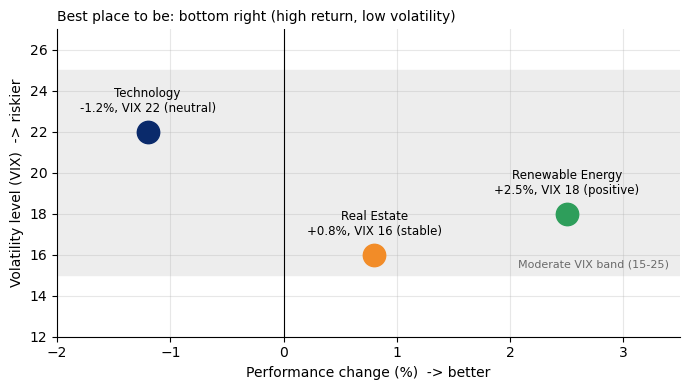

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.axhspan(15, 25, color="0.93", zorder=0)
ax.text(3.4, 15.3, "Moderate VIX band (15-25)", fontsize=8, color="dimgray", ha="right", va="bottom")
for sector, row in snapshot.iterrows():
    ax.scatter(row["Performance (%)"], row["VIX"], s=260, color=ASSET_COLORS[sector], zorder=3)
    ax.annotate(f"{sector}\n{row['Performance (%)']:+.1f}%, VIX {row['VIX']} ({row['Sentiment'].lower()})",
                (row["Performance (%)"], row["VIX"]), textcoords="offset points",
                xytext=(0, 14), ha="center", fontsize=8.5)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-2, 3.5)
ax.set_ylim(12, 27)
ax.set_xlabel("Performance change (%)  -> better")
ax.set_ylabel("Volatility level (VIX)  -> riskier")
ax.set_title("Best place to be: bottom right (high return, low volatility)", loc="left", fontsize=10)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig1_snapshot.pdf", bbox_inches="tight")
plt.show()

## 3. Current portfolio

- **Return contribution** of a holding = weight × sector performance (cash earns 0 on this snapshot).
- **Volatility exposure** = weight × sector VIX. It is a simple proxy (no correlations are given), used to see *where* the portfolio's volatility comes from.

In [4]:
SECTORS = list(snapshot.index)
ASSETS = SECTORS + ["Cash"]
performance_by_asset = snapshot["Performance (%)"].reindex(ASSETS).fillna(0.0)   # cash earns 0 on this snapshot
vix_by_asset = snapshot["VIX"].reindex(ASSETS).fillna(0.0)                       # cash has no volatility


def allocation_metrics(weights_pct):
    """Weights in % -> summary metrics, return contribution and volatility exposure of each holding."""
    weights_pct = pd.Series(weights_pct, dtype=float)
    return_contribution = weights_pct / 100 * performance_by_asset[weights_pct.index]
    volatility_exposure = weights_pct / 100 * vix_by_asset[weights_pct.index]
    summary = {
        "Total weight (%)": weights_pct.sum(),
        "Weighted performance (%)": return_contribution.sum(),
        "Weighted volatility (VIX)": volatility_exposure.sum(),
        "Tech share of volatility (%)": 100 * volatility_exposure.get("Technology", 0) / volatility_exposure.sum(),
    }
    return summary, return_contribution, volatility_exposure


current_allocation = {"Renewable Energy": 40, "Technology": 30, "Real Estate": 20, "Cash": 10}
current_summary, return_contribution, volatility_exposure = allocation_metrics(current_allocation)
pd.DataFrame({"Weight (%)": pd.Series(current_allocation),
              "Return contribution (pts)": return_contribution.round(2),
              "Volatility exposure": volatility_exposure.round(2),
              "Share of volatility (%)": (100 * volatility_exposure / volatility_exposure.sum()).round(1)})

,Weight (%),Return contribution (pts),Volatility exposure,Share of volatility (%)
Renewable Energy,40,1.00,7.2,42.4
Technology,30,-0.36,6.6,38.8
Real Estate,20,0.16,3.2,18.8
Cash,10,0.00,0.0,0.0


Technology is **30% of the capital but ~39% of the volatility exposure**, and it is the only holding losing money.
That is the "excessive exposure to high-volatility assets" the client profile asks us to avoid.

## 4. Three allocations compared

- **Current** — the client's allocation today.
- **My proposal** — Technology −8 points; 5 of them go to Renewable Energy, 3 to cash.
- **Forage example** — "reallocate 5% of cash to Renewable Energy", "reduce Technology by 5%", "retain 5% of cash".
  It never says where the 5 Technology points go. Read literally the weights sum to **95%**, so I test the most natural fix (Technology points go to cash) and also show the literal version.

In [5]:
allocations = {
    "Current": current_allocation,
    "My proposal": {"Renewable Energy": 45, "Technology": 22, "Real Estate": 20, "Cash": 13},
    "Forage example (fixed)": {"Renewable Energy": 45, "Technology": 25, "Real Estate": 20, "Cash": 10},
    "Forage example (literal)": {"Renewable Energy": 45, "Technology": 25, "Real Estate": 20, "Cash": 5},
}
comparison_rows = {}
for allocation_name, weights_pct in allocations.items():
    summary, _, _ = allocation_metrics(weights_pct)
    comparison_rows[allocation_name] = {**weights_pct, **summary}
comparison = pd.DataFrame(comparison_rows).T
comparison.round(2)

,Renewable Energy,Technology,Real Estate,Cash,Total weight (%),Weighted performance (%),Weighted volatility (VIX),Tech share of volatility (%)
Current,40.0,30.0,20.0,10.0,100.0,0.80,17.00,38.82
My proposal,45.0,22.0,20.0,13.0,100.0,1.02,16.14,29.99
Forage example (fixed),45.0,25.0,20.0,10.0,100.0,0.98,16.80,32.74
Forage example (literal),45.0,25.0,20.0,5.0,95.0,0.98,16.80,32.74


In [6]:
# The literal reading is not a valid allocation
assert comparison.loc["Forage example (literal)", "Total weight (%)"] == 95

# Export the valid allocations as a LaTeX table for the email
table_columns = ["Current", "My proposal", "Forage example (fixed)"]
column_headers = ["Current", "Proposed", "Forage example$^{*}$"]
table_lines = [r"\begin{tabular}{@{}lrrr@{}}", r"\toprule",
               " & " + " & ".join(rf"\textbf{{{header}}}" for header in column_headers) + r" \\", r"\midrule"]
for asset in ASSETS:
    table_lines.append(f"{asset} & " + " & ".join(f"{comparison.loc[column, asset]:.0f}\\%" for column in table_columns) + r" \\")
table_lines.append(r"\midrule")
table_lines.append("Weighted performance (this snapshot) & " + " & ".join(
    to_latex_number(comparison.loc[column, "Weighted performance (%)"], show_sign=True) + r"\%" for column in table_columns) + r" \\")
table_lines.append("Weighted volatility (VIX) & " + " & ".join(
    to_latex_number(comparison.loc[column, "Weighted volatility (VIX)"], "{:.1f}") for column in table_columns) + r" \\")
table_lines.append("Technology share of volatility & " + " & ".join(
    f"{comparison.loc[column, 'Tech share of volatility (%)']:.0f}\\%" for column in table_columns) + r" \\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
latex_table = "\n".join(table_lines)
(FIGURES_DIR / "table1_allocation.tex").write_text(latex_table)
print(latex_table)

\begin{tabular}{@{}lrrr@{}}
\toprule
 & \textbf{Current} & \textbf{Proposed} & \textbf{Forage example$^{*}$} \\
\midrule
Renewable Energy & 40\% & 45\% & 45\% \\
Technology & 30\% & 22\% & 25\% \\
Real Estate & 20\% & 20\% & 20\% \\
Cash & 10\% & 13\% & 10\% \\
\midrule
Weighted performance (this snapshot) & +0.80\% & +1.02\% & +0.98\% \\
Weighted volatility (VIX) & 17.0 & 16.1 & 16.8 \\
Technology share of volatility & 39\% & 30\% & 33\% \\
\bottomrule
\end{tabular}


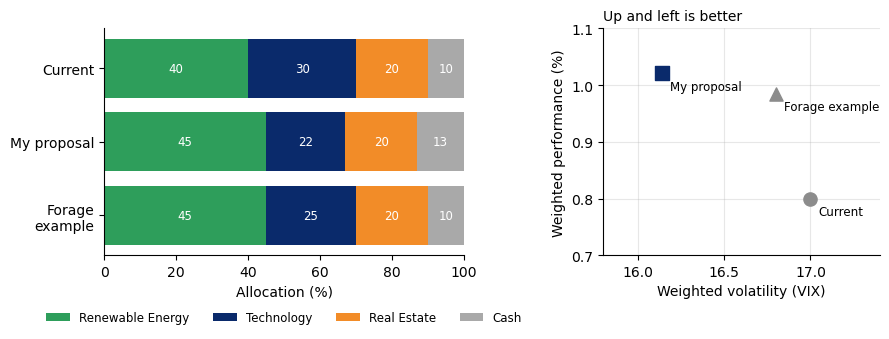

In [7]:
fig, (allocation_ax, risk_return_ax) = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
allocation_names = ["Current", "My proposal", "Forage example (fixed)"]
bar_labels = ["Current", "My proposal", "Forage\nexample"]

# Left: stacked allocation bars
bar_start = pd.Series(0.0, index=allocation_names)
for asset in ASSETS:
    asset_weights = comparison.loc[allocation_names, asset]
    allocation_ax.barh(bar_labels, asset_weights, left=bar_start.values, color=ASSET_COLORS[asset], label=asset)
    for row, (weight, start) in enumerate(zip(asset_weights, bar_start)):
        allocation_ax.text(start + weight / 2, row, f"{weight:.0f}", ha="center", va="center", color="white", fontsize=8.5)
    bar_start += asset_weights.values
allocation_ax.invert_yaxis()
allocation_ax.set_xlim(0, 100)
allocation_ax.set_xlabel("Allocation (%)")
allocation_ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False, fontsize=8.5)

# Right: return vs volatility of each allocation
for allocation_name, bar_label, marker in zip(allocation_names, bar_labels, ["o", "s", "^"]):
    volatility = comparison.loc[allocation_name, "Weighted volatility (VIX)"]
    performance = comparison.loc[allocation_name, "Weighted performance (%)"]
    point_color = "#0A2A6B" if allocation_name == "My proposal" else "0.55"
    risk_return_ax.scatter(volatility, performance, s=90, marker=marker, color=point_color, zorder=3)
    risk_return_ax.annotate(bar_label.replace("\n", " "), (volatility, performance), textcoords="offset points",
                            xytext=(6, -12), fontsize=8.5)
risk_return_ax.set_xlabel("Weighted volatility (VIX)")
risk_return_ax.set_ylabel("Weighted performance (%)")
risk_return_ax.set_xlim(15.8, 17.4)
risk_return_ax.set_ylim(0.7, 1.1)
risk_return_ax.grid(alpha=0.3)
risk_return_ax.set_title("Up and left is better", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig2_allocation.pdf", bbox_inches="tight")
plt.show()

## 5. Stress test

A single snapshot cannot say which allocation is "best" in general, so I apply three plausible shocks (sector moves in %) drawn from the client's key concerns, and compare the portfolio impact of each allocation.

In [8]:
sector_shocks = pd.DataFrame({
    "Tech sell-off continues":      {"Renewable Energy":  0.0, "Technology": -5.0, "Real Estate":  0.0},
    "Renewable policy shock":       {"Renewable Energy": -6.0, "Technology":  0.0, "Real Estate":  0.0},
    "Rate rise (+50 bp)":           {"Renewable Energy": -1.0, "Technology": -3.0, "Real Estate": -2.0},
}).T
sector_shocks["Cash"] = 0.0
stress_results = pd.DataFrame({
    allocation_name: (sector_shocks[list(allocations[allocation_name])]
                      * pd.Series(allocations[allocation_name]) / 100).sum(axis=1)
    for allocation_name in allocation_names
})
stress_results.round(2)

,Current,My proposal,Forage example (fixed)
Tech sell-off continues,-1.5,-1.10,-1.25
Renewable policy shock,-2.4,-2.70,-2.70
Rate rise (+50 bp),-1.7,-1.51,-1.60


In [9]:
table_lines = [r"\begin{tabular}{@{}lrrr@{}}", r"\toprule",
               r"Shock & \textbf{Current} & \textbf{Proposed} & \textbf{Forage example$^{*}$} \\", r"\midrule"]
for shock_name, row in stress_results.iterrows():
    table_lines.append(f"{shock_name} & " + " & ".join(to_latex_number(impact, show_sign=True) + r"\%" for impact in row) + r" \\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
latex_table = "\n".join(table_lines)
(FIGURES_DIR / "table2_stress.tex").write_text(latex_table)
print(latex_table)

\begin{tabular}{@{}lrrr@{}}
\toprule
Shock & \textbf{Current} & \textbf{Proposed} & \textbf{Forage example$^{*}$} \\
\midrule
Tech sell-off continues & \textminus{}1.50\% & \textminus{}1.10\% & \textminus{}1.25\% \\
Renewable policy shock & \textminus{}2.40\% & \textminus{}2.70\% & \textminus{}2.70\% \\
Rate rise (+50 bp) & \textminus{}1.70\% & \textminus{}1.51\% & \textminus{}1.60\% \\
\bottomrule
\end{tabular}


**Reading:**
- Cutting Technology protects the portfolio most in a tech sell-off and in a rate rise.
- The price of more Renewable Energy is a larger loss in a policy shock (45% vs 40%). This is why the email caps the sector at 45%, enters in two steps and sets a review trigger.
- The proposal loses less than the Forage example in every shock that hits Technology, because it cuts Technology by 8 points instead of 5 and holds more cash.